In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Zonal stats on local copy of median NDVI


In [51]:
infpath = r'data/sentinel2/gee_export/s2_ndvi_stats_2020_2024_DOY182-227_50m_feltfo.csv'
id_cols = ['SID', 'STATION_NA']

# Stats to keep for QC (choose from ['count', 'max', 'mean', 'median', 'min', 'stdDev'])
keep_stats_cols = ['count', 'max', 'mean', 'median', 'min', 'stdDev']

df = pd.read_csv(infpath)
df = df[id_cols + keep_stats_cols]

df

,SID,STATION_NA,count,max,mean,median,min,stdDev
0,1,Birkenes,695,0.871220,0.771193,0.780422,0.385686,0.052417
1,2,Øygardsbekken,3483,0.904807,0.719119,0.732653,0.308722,0.099811
2,3,Storgama v. dam,14,0.505657,0.390228,0.391693,0.217681,0.067279
3,4,Kårvatn,45770,0.880987,0.474475,0.503964,-0.124845,0.207423
4,5,Dalelv,8966,0.896106,0.683477,0.689438,0.055270,0.097626
5,6,"Langtjern, utløp",7586,0.854506,0.711948,0.724536,0.243816,0.068402
6,7,Svartetjern,1011,0.864755,0.750279,0.771639,0.267241,0.078552


# QC

In [52]:
bad_range = df[(df[['min','max','mean','median']] < -1).any(axis=1) |
               (df[['min','max','mean','median']] > 1).any(axis=1)]

bad_range

,SID,STATION_NA,count,max,mean,median,min,stdDev


In [53]:
df[df['count'] < 10]

,SID,STATION_NA,count,max,mean,median,min,stdDev


In [54]:
df[df['stdDev'] > df['stdDev'].quantile(0.99)]

,SID,STATION_NA,count,max,mean,median,min,stdDev
3,4,Kårvatn,45770,0.880987,0.474475,0.503964,-0.124845,0.207423


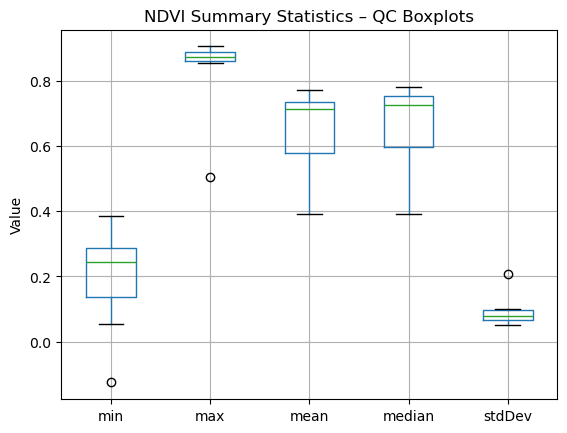

In [55]:
df[['min', 'max', 'mean', 'median', 'stdDev']].boxplot()
plt.title('NDVI Summary Statistics – QC Boxplots')
plt.ylabel('Value')
plt.show()


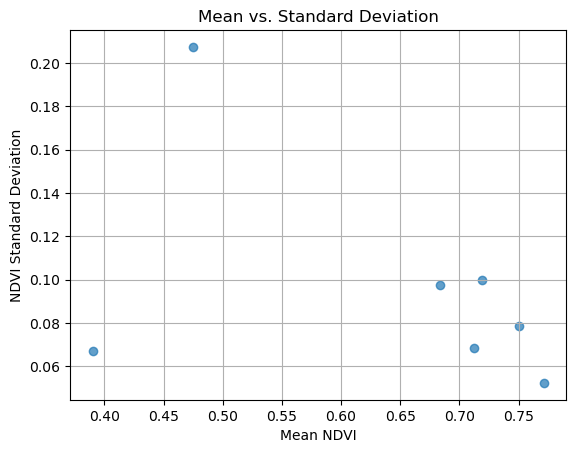

In [56]:
plt.scatter(df['mean'], df['stdDev'], alpha=0.7)
plt.xlabel('Mean NDVI')
plt.ylabel('NDVI Standard Deviation')
plt.title('Mean vs. Standard Deviation')
plt.grid(True)
plt.show()

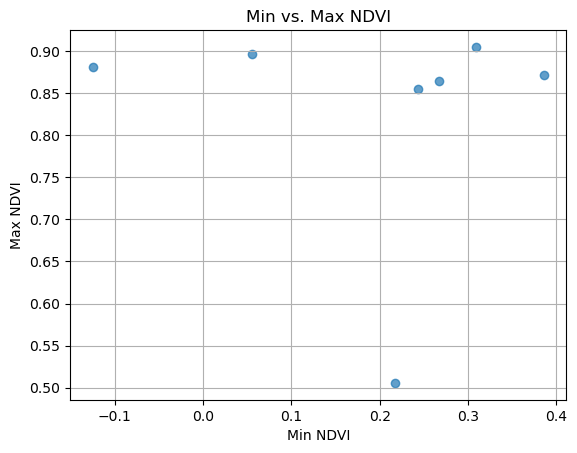

In [57]:
plt.scatter(df['min'], df['max'], alpha=0.7)
plt.xlabel('Min NDVI')
plt.ylabel('Max NDVI')
plt.title('Min vs. Max NDVI')
plt.grid(True)
plt.show()

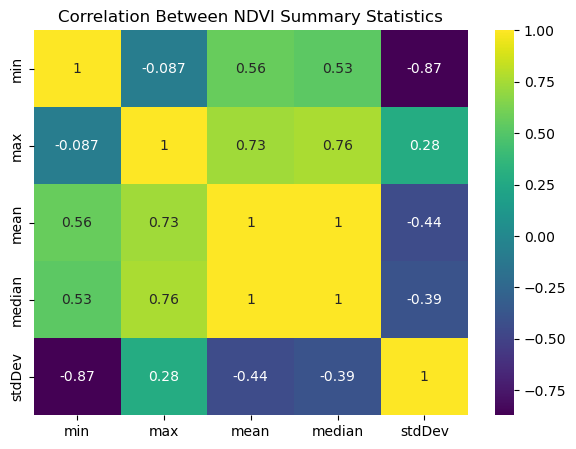

In [58]:
# Correlation heatmap (quick overview)
plt.figure(figsize=(7,5))
sns.heatmap(df[['min','max','mean','median','stdDev']].corr(), annot=True, cmap='viridis')
plt.title('Correlation Between NDVI Summary Statistics')
plt.show()

In [59]:
def highlight_outlier(s):
    is_outlier = (s < -0.1) | (s > 0.9)
    return ['background-color: yellow' if v else '' for v in is_outlier]

qc_table = (
    df[['SID','STATION_NA','min','max','mean','median','stdDev']]
    .style.apply(highlight_outlier, subset=['min','max','mean','median'])
    .background_gradient(subset=['stdDev'], cmap='Reds')
)

qc_table

,SID,STATION_NA,min,max,mean,median,stdDev
0,1,Birkenes,0.385686,0.871220,0.771193,0.780422,0.052417
1,2,Øygardsbekken,0.308722,0.904807,0.719119,0.732653,0.099811
2,3,Storgama v. dam,0.217681,0.505657,0.390228,0.391693,0.067279
3,4,Kårvatn,-0.124845,0.880987,0.474475,0.503964,0.207423
4,5,Dalelv,0.055270,0.896106,0.683477,0.689438,0.097626
5,6,"Langtjern, utløp",0.243816,0.854506,0.711948,0.724536,0.068402
6,7,Svartetjern,0.267241,0.864755,0.750279,0.771639,0.078552


# Clean (if needed) & export cleaned

In [61]:
out_fpath = r'data/sentinel2/output/s2_ndvi_stats_2020_2024_DOY182-227_50m_feltfo_forML.csv'
stats_to_export = ['mean', 'stdDev']

df[id_cols + stats_to_export].round(3).to_csv(out_fpath, index=False)